# Сол и Бор — AI for Data Analysis

Анализ на учебните данни от SoftUni с помощта на ChatGPT и Python. Сравняваме януари–септември за 2024–2026 г. Приход носят само настанените резервации. Всички суми са в евро.


In [44]:
import pymupdf

In [45]:
%pip install openpyxl

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## 1. Зареждане на данните
Четем CSV, JSON и Excel файловете. `raw` са оригиналните резервации, `reviews` са отзивите, а `config` съдържа комисионите и рекламата. `S` и `B` са имената на двата хотела.

In [46]:
from pathlib import Path
import pandas as pd
import numpy as np
import json
import math
from scipy.stats import ttest_ind, pearsonr
import matplotlib.pyplot as plt

# Папки
ROOT = Path.cwd()
DATA = ROOT
OUT = ROOT / 'results'
OUT.mkdir(exist_ok=True)

# Хотели и канали
S = 'Сол и Бор Созопол'
B = 'Сол и Бор Банско'
BK = 'Booking.com'
WEB = 'Директно — сайт'
TEL = 'Директно — телефон'
TO = 'Туроператор'

# Зареждане на CSV файловете
raw = pd.read_csv(next(DATA.glob('bookings*.csv')))
reviews = pd.read_csv(next(DATA.glob('guest*.csv')))

# Зареждане на JSON файла
config = json.loads(
    next(DATA.glob('channels*.json')).read_text(encoding='utf-8')
)

# Зареждане на Excel файла
excel_file = next(DATA.glob('rooms*.xlsx'))

def sheet(name):
    return pd.read_excel(
        excel_file,
        sheet_name=name,
        engine='openpyxl'
    )

# Брой стаи
rooms = sheet('Стаи').groupby('Хотел')['Брой стаи'].sum().to_dict()

# Променливи разходи
vc = sheet('Променливи разходи').set_index(
    ['Хотел', 'Година']
)['€ на заета стая на нощ'].to_dict()

# Постоянни разходи
fixed = sheet('Постоянни разходи')

# Разходи за реклама
marketing = pd.Series({
    m['month']: sum(s['eur'] for s in m['spend'])
    for m in config['marketing_direct']
}, name='spend')

# Бриф от собственика
print(next(DATA.glob('brief*.txt')).read_text(encoding='utf-8'))

print("\nДанните са заредени успешно!")

От: Николай Христов, собственик на „Сол и Бор“
До: екип „Анализи“
Дата: 05.10.2026
Тема: Повече гости, по-малко пари — и решение за 2027 г.

Здравейте,

През 2026 г. имаме повече гости от всякога и в двата хотела. Счетоводството обаче ми казва, че печалбата за първите девет месеца е по-ниска от миналата година. Не разбирам как.

До края на ноември трябва да взема три решения:
1. Booking.com ни предлага програмата „Preferred Partner Plus“ от 2027 г.: комисиона 18% вместо 15% срещу по-добра видимост. Да се включим ли?
2. Колко гости да очакваме през 2027 г. по месеци и колко сезонен персонал да наемем в Созопол и Банско?
3. Има ли смисъл да върнем бюджета за реклама на собствения сайт? Тази година го намалихме.

Мненията в екипа:
• Рецепцията казва, че Booking.com носи почти всички нови гости и без него ще сме празни.
• Управителят на Банско смята, че лошата зима (почти без сняг през декември 2025) е виновна за всичко.
• Счетоводителката казва, че разходите за персонал и храна растат по-

## 2. Почистване
Първо проверяваме липсващите стойности и различните изписвания. После премахваме само точните дубликати и тестовите записи. Всички промени се записват в дневник. Сумите в лева делим на 1,95583.

In [47]:
print('Размер:', raw.shape, '\nЛипсващи:', raw.isna().sum().to_string())
for c in ['hotel', 'channel', 'room_type', 'rate_plan', 'status', 'currency', 'discount_program', 'country']:
    print(c, raw[c].value_counts(dropna=False).to_dict())

def dates(s):
    return pd.to_datetime(s, format='%Y-%m-%d', errors='coerce').fillna(pd.to_datetime(s, format='%d.%m.%Y', errors='coerce'))
maps = {'hotel': {'Банско': B, 'SB Bansko': B, 'Созопол': S, 'SB Sozopol': S}, 'channel': {'booking.com': BK, 'Booking': BK, 'expedia.com': 'Expedia', 'Сайт': WEB, 'Website': WEB, 'Телефон': TEL, 'TO Балкан Травел': TO}, 'room_type': {'DBL STD': 'Двойна стандарт', 'Двойна стандартна': 'Двойна стандарт', 'DBL DLX': 'Двойна делукс', 'APT': 'Апартамент'}, 'rate_plan': {'Flexible': 'Гъвкава', 'Non-refundable': 'Невъзвратна', 'NRF': 'Невъзвратна'}, 'status': {'Checked-out': 'Настанена', 'Cancelled': 'Анулирана', 'No-show': 'Неявяване'}, 'currency': {'лв.': 'BGN', '€': 'EUR'}}
log = []

def record(rule, col, mask, frame, action):
    log.append([rule, col, int(mask.sum()), '; '.join(frame.loc[mask, col].astype(str).head(3)), action])
x = raw.copy()
record('Дубликати', 'booking_id', x.duplicated(), x, 'Премахване на точните копия')
x = x.drop_duplicates().copy()
test = x.booking_id.str.startswith('TEST-')
record('Тестови', 'booking_id', test, x, 'Премахване')
x = x.loc[~test].copy()
for c, m in maps.items():
    record('Различни изписвания', c, x[c].isin(m), x, 'Уеднаквяване')
    x[c] = x[c].replace(m)
for c in ['booked_on', 'check_in', 'check_out', 'cancel_date']:
    record('Различен формат дата', c, x[c].str.contains('\\.', na=False), x, 'ISO YYYY-MM-DD')
    x[c] = dates(x[c])
record('Десетична запетая', 'total_price', x.total_price.str.contains(','), x, 'Замяна с точка')
x.total_price = pd.to_numeric(x.total_price.str.replace(',', '.'))
record('Суми в лева', 'currency', x.currency.eq('BGN'), x, 'Деление на 1,95583')
x['total_eur'] = x.total_price / np.where(x.currency.eq('BGN'), 1.95583, 1)
invalid = (x.check_out - x.check_in).dt.days.gt(365)
record('Невъзможна година', 'check_out', invalid, x, 'check_in + записани nights')
x.loc[invalid, 'check_out'] = x.loc[invalid, 'check_in'] + pd.to_timedelta(x.loc[invalid, 'nights'], unit='D')
actual = (x.check_out - x.check_in).dt.days
wrong = actual.ne(x.nights)
record('Грешни нощувки', 'nights', wrong, x, 'Разлика между датите')
x.nights = actual
record('Липсваща държава', 'country', x.country.isna(), x, 'Неизвестна; без изтриване')
x.country = x.country.fillna('Неизвестна')
assert x.booking_id.is_unique and x.nights.gt(0).all() and (len(x) == len(raw) - 64)
log = pd.DataFrame(log, columns=['Проблем', 'Колона', 'Брой', 'Пример', 'Действие'])
log.to_csv(OUT / 'cleaning_log.csv', index=False, encoding='utf-8-sig')
x.to_csv(OUT / 'bookings_clean.csv', index=False, encoding='utf-8-sig')
print(log.to_string(index=False))
print('Статуси:', x.status.value_counts().to_dict())
print('Ръчна проверка SB-102707: 12.08 - 09.08 = 3, не 5:', x.loc[x.booking_id.eq('SB-102707'), 'nights'].item())

Размер: (11871, 16) 
Липсващи: booking_id              0
hotel                   0
channel                 0
booked_on               0
check_in                0
check_out               0
nights                  0
room_type               0
guests                  0
rate_plan               0
total_price             0
currency                0
discount_program    10723
status                  0
cancel_date         10323
country               555
hotel {'Сол и Бор Банско': 3421, 'Сол и Бор Созопол': 2419, 'Банско': 2415, 'Созопол': 1606, 'SB Bansko': 1178, 'SB Sozopol': 832}
channel {'Booking.com': 2680, 'booking.com': 1845, 'Директно — сайт': 1284, 'Директно — телефон': 1046, 'Туроператор': 893, 'Booking': 866, 'Сайт': 857, 'Expedia': 696, 'Телефон': 498, 'TO Балкан Травел': 434, 'Website': 415, 'expedia.com': 357}
room_type {'Двойна стандарт': 3401, 'Двойна делукс': 2494, 'DBL STD': 2316, 'DBL DLX': 1247, 'Двойна стандартна': 1098, 'Апартамент': 880, 'APT': 435}
rate_plan {'Гъвкава': 590

## 3. Хотелски показатели
Една резервация може да има няколко нощувки. Затова създаваме по един ред за всяка дата. `n` са нощувките, `q` е сравнимият период януари–септември. ADR = приход / нощувки. Заетост = нощувки / капацитет.

In [48]:
st = x[x.status.eq('Настанена')].copy()
n = st.loc[st.index.repeat(st.nights)].copy()
n['date'] = n.check_in + pd.to_timedelta(n.groupby(level=0).cumcount(), unit='D')
n['year'] = n.date.dt.year
n['month'] = n.date.dt.month
n['revenue'] = n.total_eur / n.nights
rates = {c['name']: c.get('commission', [{'pct': 0}])[0]['pct'] / 100 for c in config['channels']}
n['commission'] = n.revenue * n.channel.map(rates)
n['variable'] = [vc.get((h, y), vc[h, 2026]) for h, y in zip(n.hotel, n.year)]
n = n[n.date.between('2024-01-01', '2026-09-30')].copy()
q = n[n.month.le(9)].copy()

def capacity(h, y, m):
    return rooms[h] * pd.Period(f'{y}-{m:02}', freq='M').days_in_month if h == S and 4 <= m <= 10 or (h == B and m != 11) else 0
k = q.groupby(['hotel', 'year']).agg(nights=('date', 'size'), revenue=('revenue', 'sum'), commission=('commission', 'sum'), variable=('variable', 'sum'))
k['capacity'] = [sum((capacity(h, y, m) for m in range(1, 10))) for h, y in k.index]
k['occupancy'] = k.nights / k.capacity
k['ADR'] = k.revenue / k.nights
k['RevPAR'] = k.revenue / k.capacity
k['NetRevPAR'] = (k.revenue - k.commission) / k.capacity
monthly = n.groupby(['hotel', 'year', 'month']).size()
print(k.round(3).to_string())
print('Ръчна проверка Созопол юли 2026:', monthly[S, 2026, 7], '/ 1302 =', monthly[S, 2026, 7] / 1302)
print('Дневен максимум:', n.groupby(['hotel', 'date']).size().groupby(level=0).max().to_dict())
k.to_csv(OUT / 'hotel_kpis.csv')

                        nights     revenue  commission  variable  capacity  occupancy      ADR  RevPAR  NetRevPAR
hotel             year                                                                                           
Сол и Бор Банско  2024    4807  414345.925   27883.795   91333.0      9864      0.487   86.196  42.006     39.179
                  2025    5016  460314.080   37250.466  100320.0      9828      0.510   91.769  46.837     43.047
                  2026    5243  475213.916   42919.927  112724.5      9828      0.533   90.638  48.353     43.986
Сол и Бор Созопол 2024    4376  457841.748   30679.429   91896.0      7686      0.569  104.626  59.568     55.577
                  2025    4577  508871.422   41296.306  100694.0      7686      0.595  111.180  66.208     60.835
                  2026    5139  558182.503   52224.708  125905.5      7686      0.669  108.617  72.623     65.828
Ръчна проверка Созопол юли 2026: 1189 / 1302 = 0.9132104454685099
Дневен максимум: {'Сол

## 4. Приходи и разходи
`p` е общата таблица по години. Изваждаме комисионите, променливите и постоянните разходи и рекламата от приходите. Мостът показва колко всяка промяна влияе на печалбата.

In [49]:
p = k.groupby('year')[['nights', 'revenue', 'commission', 'variable', 'capacity']].sum()
p['fixed'] = fixed[fixed['Месец'].le(9)].groupby('Година')['€'].sum()
p['marketing'] = marketing[marketing.index.str[-2:].astype(int) <= 9].groupby(marketing[marketing.index.str[-2:].astype(int) <= 9].index.str[:4].astype(int)).sum()
p['profit'] = p.revenue - p.commission - p.variable - p.fixed - p.marketing
ch = pd.crosstab(q.year, q.channel)
shares = ch.div(ch.sum(axis=1), axis=0)
p['direct'] = shares[WEB] + shares[TEL]
bridge = (p.loc[2026, ['revenue', 'commission', 'variable', 'fixed', 'marketing']] - p.loc[2025, ['revenue', 'commission', 'variable', 'fixed', 'marketing']]) * [1, -1, -1, -1, -1]
g = q[(q.year == 2026) & q.channel.eq(BK)]
genius = g[g.discount_program.eq('Genius')]
genius_share = len(genius) / len(g)
genius_cost = genius.revenue.sum() / 9
flex = x[x.rate_plan.eq('Гъвкава') & x.check_in.dt.year.isin([2025, 2026]) & x.check_in.dt.month.le(9)].copy()
flex['group'] = flex.channel.replace({WEB: 'Директно', TEL: 'Директно'})
canc = flex.groupby('group').status.agg(total='size', cancelled=lambda z: z.eq('Анулирана').sum())
canc['rate'] = canc.cancelled / canc.total
assert np.isclose(bridge.sum(), p.profit.diff().iloc[-1])
print(p.round(2).to_string())
print('Мост:', bridge.round(2).to_dict())
print('Канали:\n', shares.round(4))
print('Genius:', len(genius), len(g), genius_share, genius_cost)
print(canc)
p.to_csv(OUT / 'financials.csv')
shares.to_csv(OUT / 'channel_shares.csv')
canc.to_csv(OUT / 'cancellations.csv')
print('Проверка: 100 € след Genius означава 100/0.9-100 = 11.11 € отстъпка.')

      nights     revenue  commission  variable  capacity   fixed  marketing    profit  direct
year                                                                                         
2024    9183   872187.67    58563.22  183229.0     17550  535800   33307.78  61287.67    0.44
2025    9593   969185.50    78546.77  201014.0     17514  564000   31240.95  94383.78    0.36
2026   10382  1033396.42    95144.64  238630.0     17514  609120   20072.09  70429.69    0.29
Мост: {'revenue': 64210.92, 'commission': -16597.86, 'variable': -37616.0, 'fixed': -45120.0, 'marketing': 11168.86}
Канали:
 channel  Booking.com  Expedia  Директно — сайт  Директно — телефон  \
year                                                                 
2024          0.3509   0.0764           0.2818              0.1596   
2025          0.4154   0.0914           0.2257              0.1392   
2026          0.4957   0.0936           0.1802              0.1128   

channel  Туроператор  
year                  
2024   

## 5. Отзиви
Разпределяме отзивите по ключови думи. Welch t-test проверява дали разликата между средните оценки е статистически значима. При p под 0,05 имаме достатъчно основание да приемем, че има промяна. Авторът трябва лично да прегледа 20-те текста.

In [50]:
r = reviews[reviews.stay_month.str[-2:].astype(int) <= 9].copy()
r['year'] = r.stay_month.str[:4].astype(int)

def topic(t):
    t = t.lower()
    for label, terms in [('Шум', ['шумно', 'noisy']), ('Закуска', ['закуската']), ('Басейн', ['басейна']), ('Интернет', ['интернет', 'wi-fi']), ('Паркинг', ['паркинг'])]:
        if any((a in t for a in terms)):
            return label
    return 'Без забележка'
r['topic'] = r.text.map(topic)
ratings = r.groupby(['hotel', 'year']).rating.agg(['mean', 'count', 'std'])
tests = {h: ttest_ind(r.loc[(r.hotel == h) & (r.year == 2025), 'rating'], r.loc[(r.hotel == h) & (r.year == 2026), 'rating'], equal_var=False).pvalue for h in [S, B]}
rr = r[(r.hotel == S) & (r.year == 2026)]
topics = rr.topic.value_counts()
print(ratings)
print('Welch', tests)
print('Теми', topics, topics / len(rr))
sample = r.sample(20, random_state=42)[['review_id', 'text', 'topic']].copy()
print(sample.to_string(index=False))
ratings.to_csv(OUT / 'ratings.csv')
r.to_csv(OUT / 'classified_reviews.csv', index=False, encoding='utf-8-sig')
sample.to_csv(OUT / 'review_sample.csv', index=False, encoding='utf-8-sig')
labels = ['Шум', 'Без забележка', 'Шум', 'Без забележка', 'Без забележка', 'Без забележка', 'Без забележка', 'Без забележка', 'Без забележка', 'Закуска', 'Паркинг', 'Закуска', 'Паркинг', 'Без забележка', 'Без забележка', 'Без забележка', 'Интернет', 'Без забележка', 'Без забележка', 'Без забележка']
sample['reviewed_by_AI'] = labels
sample['match'] = sample.topic.eq(sample.reviewed_by_AI)
sample.to_csv(OUT / 'review_sample_verified.csv', index=False, encoding='utf-8-sig')
print('Преглед на 20 текста:', sample.match.sum(), '/ 20; авторът да потвърди лично.')

                            mean  count       std
hotel             year                           
Сол и Бор Банско  2024  8.834211    152  0.805865
                  2025  8.891379    174  0.832911
                  2026  8.829032    155  0.858870
Сол и Бор Созопол 2024  8.978632    117  0.663563
                  2025  8.983721    129  0.826399
                  2026  8.345133    113  0.940744
Welch {'Сол и Бор Созопол': np.float64(7.104782568379813e-08), 'Сол и Бор Банско': np.float64(0.5054652589127335)}
Теми topic
Без забележка    47
Шум              38
Закуска          24
Басейн            4
Name: count, dtype: int64 topic
Без забележка    0.415929
Шум              0.336283
Закуска          0.212389
Басейн           0.035398
Name: count, dtype: float64
review_id                                                           text         topic
  R-00757 Чудесна гледка към морето. Шумно вечер от заведението отсреща.           Шум
  R-00883                                           Уютн

## 6. Графики
Три графики: заетост и резултат, промяната в печалбата и дяловете на каналите.

In [51]:
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10})
fig, ax = plt.subplots(figsize=(7, 3.3))
ax.plot(p.index, p.profit / 1000, marker='o', label='Резултат, хил. €')
ax.set_xticks(p.index)
ax.set_ylabel('Хил. €')
ax2 = ax.twinx()
ax2.plot(p.index, p.nights / p.capacity * 100, marker='s', color='tab:orange')
ax2.set_ylabel('Заетост, %')
ax.set_title('Резултат и заетост (ян.–септ.)')
fig.tight_layout()
fig.savefig(OUT / 'story_occupancy.png', dpi=160)
plt.close(fig)
fig, ax = plt.subplots(figsize=(7, 3.2))
labels = ['Приходи', 'Комисиони', 'Променливи', 'Постоянни', 'Реклама']
base = p.loc[2025, 'profit'] / 1000
running = base
ax.bar(0, base, color='#487b96')
for i, v in enumerate(bridge / 1000, 1):
    ax.bar(i, abs(v), bottom=min(running, running + v), color='#498b70' if v >= 0 else '#b85f58')
    running += v
ax.bar(6, running, color='#487b96')
ax.set_xticks(range(7), ['2025'] + labels + ['2026'], rotation=18)
ax.set_ylabel('Хил. €')
ax.set_title('Мост на резултата')
fig.tight_layout()
fig.savefig(OUT / 'story_bridge.png', dpi=160)
plt.close(fig)
fig, ax = plt.subplots(figsize=(7, 3.2))
(shares * 100).plot.bar(stacked=True, ax=ax)
ax.set_ylabel('% от нощувките')
ax.set_xlabel('')
ax.legend(fontsize=7, loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=3)
ax.set_title('Микс на каналите')
fig.tight_layout()
fig.savefig(OUT / 'story_channels.png', dpi=160)
plt.close(fig)

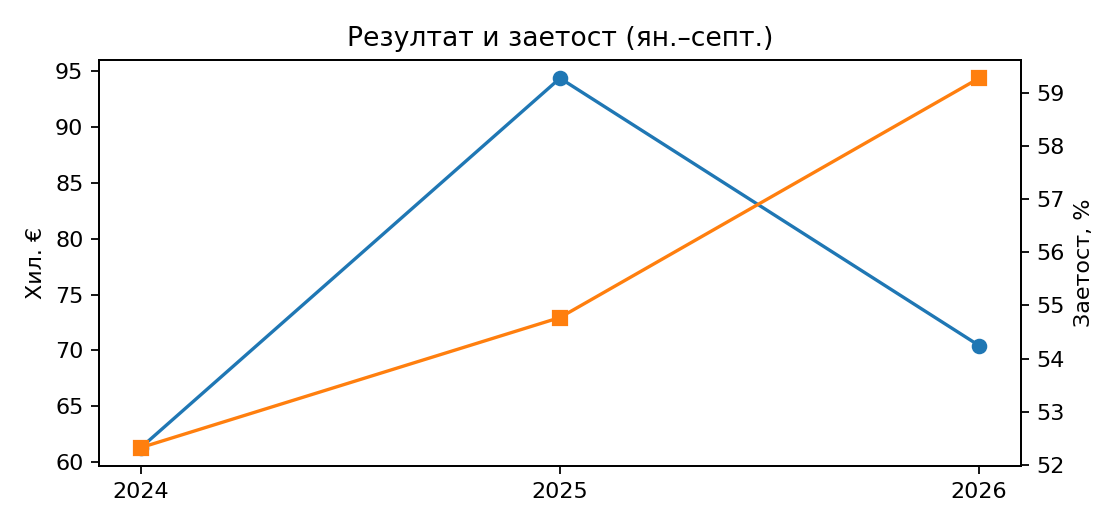

In [52]:
from IPython.display import Image, display
display(Image(filename='results/story_occupancy.png'))

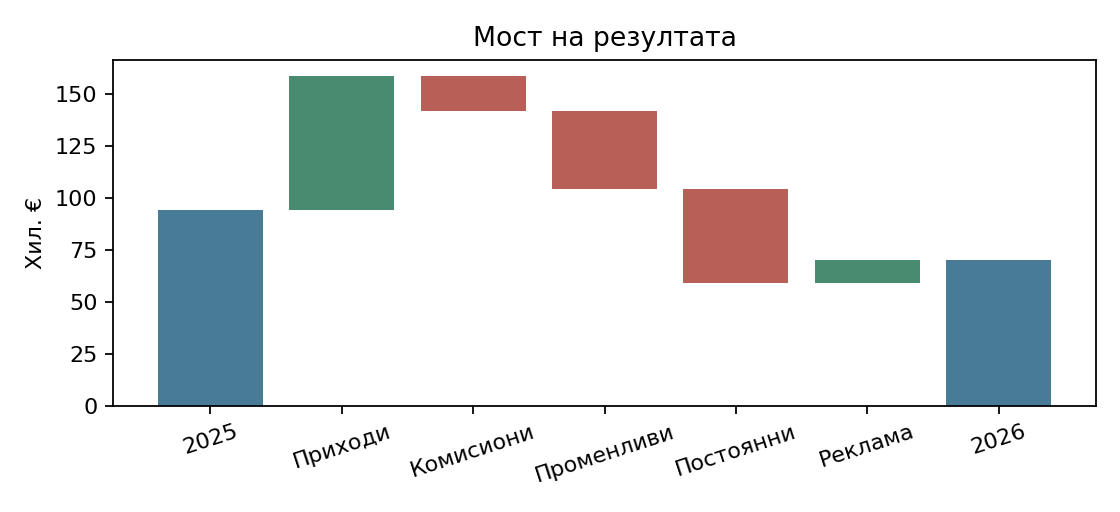

In [53]:
from IPython.display import Image, display
display(Image(filename='results/story_bridge.png'))

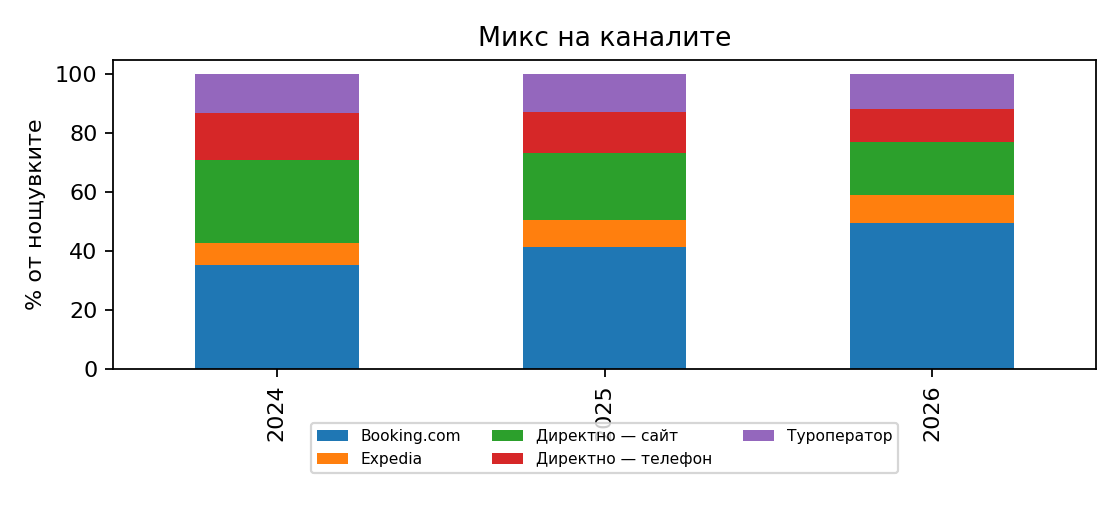

In [54]:
from IPython.display import Image, display
display(Image(filename='results/story_channels.png'))

## 7. Прогноза и Booking.com
Изключваме еднократната група и слабия декември. Даваме по-голяма тежест на последната година. Сценариите са ±10% от базовата прогноза, ограничени от броя стаи. Един сезонен служител е нужен на 120 нощувки. За Booking.com сравняваме допълнителната комисиона с приноса от нови гости.

In [55]:
clusters = st.groupby(['hotel', 'booked_on', 'check_in']).size().sort_values(ascending=False)
print('Групи:', clusters.head(8))
event_ids = st.loc[(st.hotel == S) & st.booked_on.eq('2026-02-20') & st.check_in.eq('2026-06-12'), 'booking_id']
normal = n[~n.booking_id.isin(event_ids)]
hist = normal.groupby(['hotel', 'year', 'month']).size()
print('Декември Банско:', monthly.get((B, 2024, 12), 0), monthly.get((B, 2025, 12), 0))
print('Група нощувки:', n.booking_id.isin(event_ids).sum())
forecast = []
for h in [S, B]:
    for m in range(1, 13):
        vals = [hist.get((h, y, m), 0) for y in [2024, 2025, 2026]]
        if h == B and m == 12:
            base = vals[0]
        elif m > 9:
            base = np.mean(vals[:2])
        else:
            base = np.average(vals, weights=[1, 2, 3])
        cap = capacity(h, 2027, m)
        estimates = [min(cap, round(base * f)) for f in [0.9, 1, 1.1]]
        forecast.append([h, m, cap, *estimates, *[math.ceil(v / 120) for v in estimates]])
f = pd.DataFrame(forecast, columns=['hotel', 'month', 'capacity', 'low', 'base', 'high', 'staff_low', 'staff_base', 'staff_high'])
f.to_csv(OUT / 'forecast_2027.csv', index=False, encoding='utf-8-sig')
print(f.to_string(index=False))
print('Годишно', f.groupby('hotel')[['low', 'base', 'high']].sum())
print('Пик', f.groupby('hotel')[['staff_low', 'staff_base', 'staff_high']].max())
extra = 0.03 * g.revenue.sum()
margin = (g.revenue * 0.82 - g.variable).mean()
breakeven = math.ceil(extra / margin)
print('Доп. комисиона', extra, 'марж', margin, 'праг', breakeven)
scenarios = []
for name, growth, switch in [('Песимистичен', 0.05, 0.6), ('Базов', 0.1, 0.3), ('Оптимистичен', 0.2, 0.1)]:
    delta = -extra
    new = shift = 0
    for (h, m), z in g.groupby(['hotel', 'month']):
        adr = z.revenue.mean()
        direct = q[(q.hotel == h) & (q.year == 2026) & (q.month == m) & q.channel.isin([WEB, TEL])]
        free = max(0, capacity(h, 2026, m) - monthly.get((h, 2026, m), 0))
        moved = min(len(direct), len(z) * growth * switch)
        added = min(free, len(z) * growth * (1 - switch))
        delta += added * (adr * 0.82 - vc[h, 2026]) + moved * (adr * 0.82 - (direct.revenue.mean() if len(direct) else adr))
        new += added
        shift += moved
    scenarios.append([name, growth, switch, new, shift, delta])
sc = pd.DataFrame(scenarios, columns=['scenario', 'growth', 'switch', 'new', 'moved', 'delta'])
print(sc.to_string(index=False))
sc.to_csv(OUT / 'preferred_scenarios.csv', index=False, encoding='utf-8-sig')
freepeak = {(h, m): capacity(h, 2026, m) - monthly.get((h, 2026, m), 0) for h in [S, B] for m in [7, 8]}
print('Свободни стаи-нощувки', freepeak)
print('Ръчна проверка:', math.ceil(121 / 120), 'служители при 121 нощувки')

Групи: hotel              booked_on   check_in  
Сол и Бор Созопол  2026-02-20  2026-06-12    18
Сол и Бор Банско   2023-12-29  2024-01-04     4
Сол и Бор Созопол  2026-07-11  2026-07-16     4
                   2026-07-04  2026-07-10     4
Сол и Бор Банско   2026-01-22  2026-02-03     4
                   2024-02-07  2024-02-15     4
Сол и Бор Созопол  2026-08-05  2026-08-14     4
                   2024-06-25  2024-07-09     3
dtype: int64
Декември Банско: 619 345
Група нощувки: 54
            hotel  month  capacity  low  base  high  staff_low  staff_base  staff_high
Сол и Бор Созопол      1         0    0     0     0          0           0           0
Сол и Бор Созопол      2         0    0     0     0          0           0           0
Сол и Бор Созопол      3         0    0     0     0          0           0           0
Сол и Бор Созопол      4      1260  270   300   330          3           3           3
Сол и Бор Созопол      5      1302  543   603   663          5           6  

## 8. Политики и договори
Това са отговори на ChatGPT, сверени по точките в предоставения PDF. За окончателно предаване трябва да се създаде отделен асистент и да се добави линк или screenshot.

In [56]:
import fitz, re
pdf = fitz.open(next(DATA.glob('policies*')))
policy_text = '\n'.join((page.get_text() for page in pdf))
clauses = {m.group(1): m.group(2).strip() for m in re.finditer('(?ms)^\\s*(\\d+\\.\\d+)\\.\\s+(.*?)(?=^\\s*\\d+\\.\\d+\\.\\s|^\\s*\\d+\\.\\s+[А-Я]|\\Z)', policy_text)}
qa = [('Гост с гъвкава цена анулира на 10 юли престоя си в Созопол от 20 юли. Дължи ли такса и каква?', 'Да. Остават 10 дни, а срокът през юли е 14 дни. Дължи цената на първата нощувка.', ['2.1', '2.2']), ('Дължим ли комисиона на Booking.com за анулирана резервация, за която гостът не е платил такса?', 'Не. При анулиране без такса не се дължи комисиона.', ['3.2']), ('Върху коя цена се изчислява комисионата за резервация с отстъпка Genius?', 'Върху цената след 10% отстъпка.', ['3.4']), ('Можем ли на собствения сайт да предложим 5% по-ниска публична цена от тази в Booking.com?', 'Не, за същата стая и условия документът изисква ценови паритет.', ['3.3']), ('До коя дата туроператорът трябва да освободи неизползваните стаи от квотата за 1 август в Созопол?', 'До 11 юли (1 август минус 21 дни).', ['5.3']), ('Гост иска да дойде в Банско с куче от 12 кг. Можем ли да го настаним?', 'Не с кучето: ограничението е до 10 кг.', ['1.4']), ('Каква комисиона взема Airbnb?', 'В документа няма информация за комисионата на Airbnb.', [])]
for question, answer, refs in qa:
    print(question, '\n', answer, '\n', '; '.join((f"т. {c}: {clauses.get(c, 'ПРОВЕРИ')}" for c in refs)) or 'Няма цитат — липсва в документа', '\n')
assert all((c in clauses for _, _, refs in qa for c in refs))
assert 'Airbnb' not in policy_text
assert (pd.Timestamp('2026-08-01') - pd.Timedelta(days=21)).day == 11

Гост с гъвкава цена анулира на 10 юли престоя си в Созопол от 20 юли. Дължи ли такса и каква? 
 Да. Остават 10 дни, а срокът през юли е 14 дни. Дължи цената на първата нощувка. 
 т. 2.1: Гъвкава цена: безплатно анулиране до 7 дни преди пристигане. За престой в Созопол от
1 юли до 31 август — до 14 дни преди пристигане.; т. 2.2: При по-късно анулиране се дължи цената на първата нощувка. 

Дължим ли комисиона на Booking.com за анулирана резервация, за която гостът не е платил такса? 
 Не. При анулиране без такса не се дължи комисиона. 
 т. 3.2: Комисиона не се дължи за анулирани резервации без такса за анулиране и за неявяване,
за което хотелът не е получил плащане. 

Върху коя цена се изчислява комисионата за резервация с отстъпка Genius? 
 Върху цената след 10% отстъпка. 
 т. 3.4: Програма Genius (от 01.01.2026): отстъпка 10% за потребители с Genius статус.
Отстъпката се поема от хотела. Комисионата се изчислява върху цената след отстъпката. 

Можем ли на собствения сайт да предложим 5

## 9. Реклама
Сравняваме месечната реклама с резервациите по датата на резервиране, а не на престоя. Корелацията показва връзка, но не доказва причинност.

In [57]:
ad = marketing.to_frame()
booked = x[x.channel.isin([WEB, TEL])].groupby(x.booked_on.dt.strftime('%Y-%m')).size()
web = x[x.channel.eq(WEB)].groupby(x.booked_on.dt.strftime('%Y-%m')).size()
ad['direct'] = booked.reindex(ad.index, fill_value=0)
ad['website'] = web.reindex(ad.index, fill_value=0)
corr = pearsonr(ad.spend, ad.direct)
corr_web = pearsonr(ad.spend, ad.website)
ad.to_csv(OUT / 'marketing_by_booking_month.csv')
print(ad.to_string())
print('Pearson direct', corr, 'website', corr_web)
print('Проверка януари 2026:', config['marketing_direct'][24], ad.loc['2026-01'].to_dict())
print('Ограничение: резервации за след 30.09.2026 липсват; последните месеци са непълни по booked_on.')

           spend  direct  website
2024-01  4526.34     131       71
2024-02  4446.33     117       81
2024-03  3059.86     118       71
2024-04  3033.68     124       71
2024-05  4228.47     165      116
2024-06  4702.55     203      131
2024-07  2983.23     221      133
2024-08  3245.31     176      115
2024-09  3082.01     108       59
2024-10  2453.85      58       41
2024-11  2633.80      86       61
2024-12  3151.51     110       68
2025-01  4194.10     110       75
2025-02  4257.09      93       62
2025-03  3102.70     100       61
2025-04  3143.86     123       72
2025-05  3910.19     159       90
2025-06  3913.26     163      104
2025-07  2887.84     185      108
2025-08  2950.10     149       91
2025-09  2881.81      95       57
2025-10  2335.55      44       26
2025-11  2216.59      48       38
2025-12  3006.74      91       60
2026-01  2823.60     100       56
2026-02  2614.32     116       63
2026-03  2034.78      89       62
2026-04  1778.56     104       75
2026-05  2680.